# Fare grafici (fatti bene) con Python


Potete scaricare questa pagina in formato Jupyter notebook cliccando sul pulsante a forma di freccia orientata verso il basso che trovate in alto a destra. Usate il notebook per esercitarvi e fare delle prove!

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# nel notebook i grafici compaiono sotto la cella; in uno script .py serve plt.show()
%matplotlib inline
plt.rcParams["figure.figsize"] = (6, 4)   # dimensione di default delle figure (in pollici)
plt.rcParams["figure.dpi"] = 100

## Ripasso lampo

A Laboratorio di Calcolo avete visto che:

* `plt.plot(x, y)` aggiunge una curva al grafico (`x` e `y` devono avere la stessa lunghezza)
* ogni chiamata a `plt.plot` aggiunge una curva **sullo stesso grafico**
* il terzo argomento (notazione compatta) sceglie colore, simbolo e tipo di linea: `'ro'`, `'g<-.'`, `'b--'`, ...
* in alternativa: `color=...`, `marker=...`, `linestyle=...`, `linewidth=...`
* `plt.xlim`, `plt.ylim` impostano gli intervalli degli assi
* `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend` aggiungono titolo, etichette e legenda
* `np.loadtxt(..., unpack=True, usecols=...)` legge colonne di dati da file
* `plt.savefig("nome.png")` salva la figura (da chiamare **prima** di `plt.show()`)

Ecco tutto in una cella:

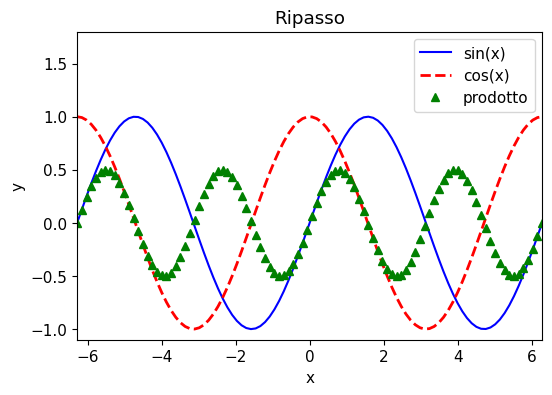

In [43]:
x = np.linspace(-2 * np.pi, 2 * np.pi, 100)

plt.plot(x, np.sin(x), 'b-', label="sin(x)")
plt.plot(x, np.cos(x), color='r', linestyle='--', linewidth=2, label="cos(x)")
plt.plot(x, np.sin(x) * np.cos(x), 'g^', label="prodotto")  # un punto ogni 5

plt.xlim(-2 * np.pi, 2 * np.pi)
plt.ylim(-1.1, 1.8) # 1.8 così da non sovrapporre la legenda alle curve
plt.title("Ripasso")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.savefig("ripasso.png")
plt.show()

## Il sistema modello: la caduta di un grave

Riprendiamo il problema dell'Esercitazione 1. Con l'asse $y$ verticale orientato verso l'alto:

$$
\frac{dy}{dt} = v, \qquad \frac{dv}{dt} = -g, \qquad g > 0,
$$

con soluzione analitica

$$
y(t) = y_0 + v_0 t - \frac{1}{2} g t^2, \qquad v(t) = v_0 - g t.
$$

Usiamo $g = 9.81\ \mathrm{m/s^2}$, $y_0 = 10\ \mathrm{m}$, $v_0 = 5\ \mathrm{m/s}$ (corpo lanciato verso l'alto da 10 m di altezza).

**Attenzione**: nel codice i numeri *non hanno unità*. Siamo noi a decidere (e a ricordare!) che `y0 = 10.0` significa 10 metri. Il grafico è il posto dove questa informazione deve ricomparire.

In [44]:
# parametri (unità SI: m, s)
g = 9.81           # m/s^2
y0, v0 = 10.0, 5.0 # m, m/s

Qui sotto c'è un piccolo integratore (metodo di Eulero) che produce lo stesso output del vostro programma C dell'Esercitazione 1: un file con **tre colonne** `t y v`. Così possiamo esercitarci anche con la lettura da file, esattamente come farete con l'output dei vostri programmi.

In [45]:
def caduta(dt, nsteps, y0, v0, g, nomefile):
    # integra la caduta libera con il metodo di Eulero; restituisce (ed eventualmente salva) le colonne t y v
    t, y, v = 0.0, y0, v0
    righe = [(t, y, v)]
    for _ in range(nsteps):
        y, v = y + v * dt, v - g * dt
        t += dt
        righe.append((t, y, v))
    dati = np.array(righe)
    if nomefile is not None:
        np.savetxt(nomefile, dati)
    return dati

dt = 0.1      # s
nsteps = 20   # 2 s in tutto
caduta(dt, nsteps, y0, v0, g, "caduta.dat")

# rileggiamo il file come fareste con l'output del programma C
t, y, v = np.loadtxt("caduta.dat", unpack=True)

# soluzione analitica sugli stessi tempi
y_an = y0 + v0 * t - 0.5 * g * t**2
v_an = v0 - g * t

## Anatomia di un grafico inutile

Ecco un grafico "tecnicamente corretto": il codice funziona e le curve sono giuste.

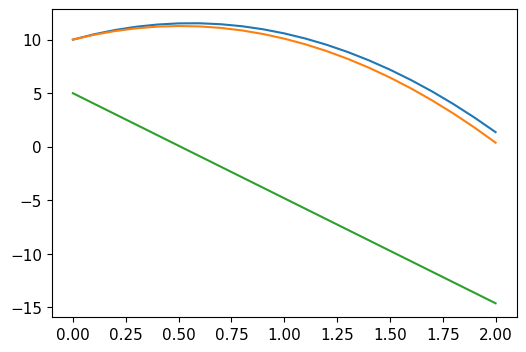

In [46]:
plt.plot(t, y)
plt.plot(t, y_an)
plt.plot(t, v)
plt.show()

**Domande** (rispondete prima di andare avanti):

* Cosa c'è sull'asse orizzontale? E su quello verticale?
* Quale curva è quale? Quale è quella "giusta"?
* Il numero `2.0` sull'asse orizzontale sono 2 secondi? 2 millisecondi? 2 passi di integrazione?
* Le tre curve rappresentano tutte la stessa grandezza? Ha senso che condividano lo stesso asse $y$?
* Se vi mostrassi solo questa figura in sede d'esame, cosa potreste concluderne?

Aggiungere etichette "a caso" non migliora molto le cose:

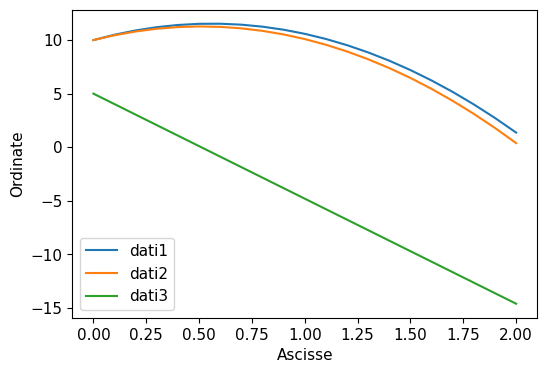

In [47]:
plt.plot(t, y, label="dati1")
plt.plot(t, y_an, label="dati2")
plt.plot(t, v, label="dati3")
plt.xlabel("Ascisse")
plt.ylabel("Ordinate")
plt.legend()
plt.show()

> 💡 **Regola d'oro**: un grafico deve essere comprensibile **da solo**, senza leggere il codice che l'ha prodotto. Chi lo guarda deve sapere *quale grandezza fisica* è su ciascun asse, *in quale unità di misura*, e *cosa rappresenta* ciascuna curva.

## Etichette, unità di misura e legende

### Etichette degli assi: grandezza + unità

Un'etichetta d'asse deve contenere **il nome o il simbolo della grandezza** e **la sua unità di misura**. Le convenzioni più comuni sono:

| Stile | Esempio | Note |
|---|---|---|
| parentesi tonde | `t (s)` | molto diffuso |
| parentesi quadre | `t [s]` | molto diffuso |
| rapporto | `t / s` | raccomandato da ISO/IUPAP: l'asse riporta il numero puro $t/\mathrm{s}$ |

Sceglietene una e **usatela in modo coerente** in tutti i grafici di una relazione.

Nel grafico qui sotto notate anche un'altra scelta piuttosto comune: i **risultati numerici** (che esistono solo nei tempi discreti $t_n = n\,\Delta t$) sono disegnati con dei **simboli**, la **soluzione analitica** (che è una funzione continua) con una **linea**, calcolata su una griglia di tempi molto più fitta.

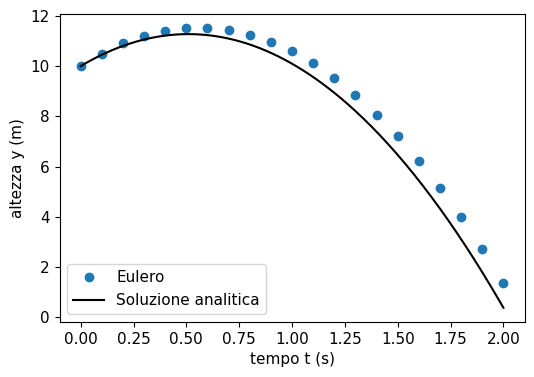

In [48]:
t_fine = np.linspace(0, t[-1], 200)   # griglia fitta per la curva teorica
y_fine = y0 + v0 * t_fine - 0.5 * g * t_fine**2

plt.plot(t, y, 'o', label="Eulero")
plt.plot(t_fine, y_fine, 'k-', label="Soluzione analitica")
plt.xlabel("tempo t (s)")
plt.ylabel("altezza y (m)")
plt.legend()
plt.show()

Già molto meglio: ora sappiamo cosa stiamo guardando e possiamo *leggere* il grafico (ad esempio: il corpo arriva a circa 11 m di altezza dopo circa mezzo secondo e tocca terra dopo poco più di 2 s).

### Grandezze diverse ⇒ assi diversi

Posizione e velocità hanno unità diverse: metterle sullo stesso asse $y$ non ha senso (il "valore 5" sarebbe 5 m o 5 m/s?). La soluzione è usare **più pannelli**, ciascuno con le proprie etichette:

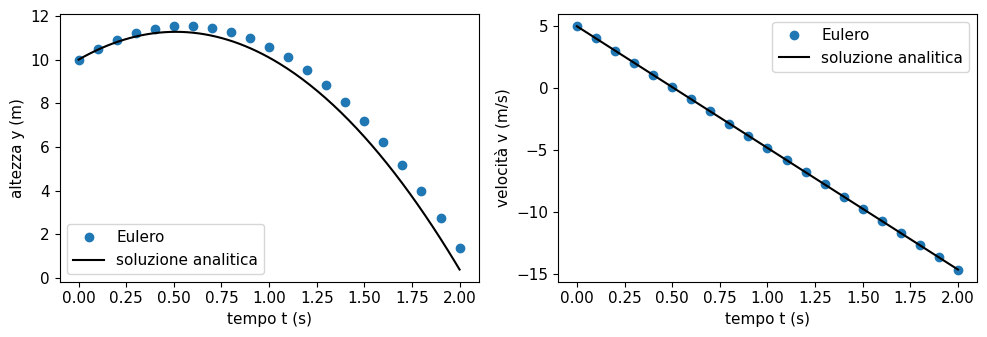

In [49]:
v_fine = v0 - g * t_fine

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(t, y, 'o', label="Eulero")
axes[0].plot(t_fine, y_fine, 'k-', label="soluzione analitica")
axes[0].set_xlabel("tempo t (s)")
axes[0].set_ylabel("altezza y (m)")
axes[0].legend()

axes[1].plot(t, v, 'o', label="Eulero")
axes[1].plot(t_fine, v_fine, 'k-', label="soluzione analitica")
axes[1].set_xlabel("tempo t (s)")
axes[1].set_ylabel("velocità v (m/s)")
axes[1].legend()

fig.tight_layout()
plt.show()

> **Nota sull'interfaccia "a oggetti"**: qui abbiamo usato `fig, axes = plt.subplots(...)` per avere più pannelli. Ogni pannello (`axes[0]`, `axes[1]`, ...) ha i suoi metodi, che corrispondono quasi uno a uno alle funzioni `plt.` che conoscete:
>
> | `pyplot` | oggetto `ax` |
> |---|---|
> | `plt.plot(...)` | `ax.plot(...)` |
> | `plt.xlabel(...)` | `ax.set_xlabel(...)` |
> | `plt.ylabel(...)` | `ax.set_ylabel(...)` |
> | `plt.title(...)` | `ax.set_title(...)` |
> | `plt.xlim(...)` | `ax.set_xlim(...)` |
> | `plt.legend()` | `ax.legend()` |

### L'unità deve corrispondere ai *numeri* riportati sull'asse

L'unità nell'etichetta non è decorazione: deve essere quella dei numeri effettivamente graficati. Se convertite i dati, cambiate anche l'etichetta.

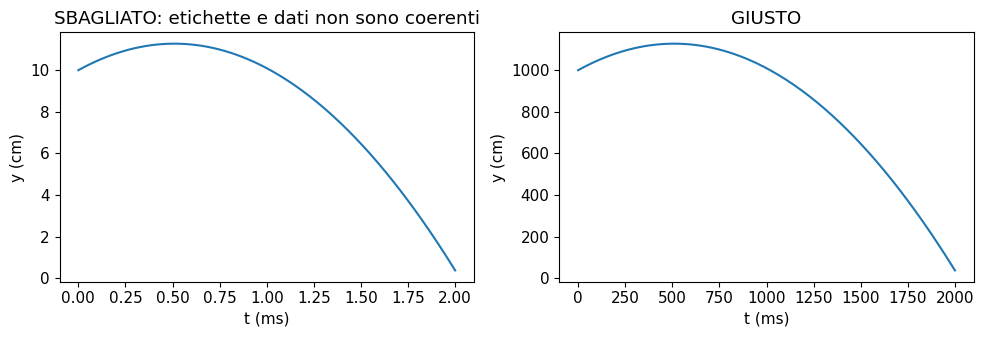

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# SBAGLIATO: i dati sono in s e m, ma le etichette dicono ms e cm
axes[0].plot(t_fine, y_fine)
axes[0].set_xlabel("t (ms)")
axes[0].set_ylabel("y (cm)")
axes[0].set_title("SBAGLIATO: etichette e dati non sono coerenti")

# GIUSTO: convertiamo i dati e scriviamo le unità corrispondenti
axes[1].plot(t_fine * 1e3, y_fine * 1e2)
axes[1].set_xlabel("t (ms)")
axes[1].set_ylabel("y (cm)")
axes[1].set_title("GIUSTO")

fig.tight_layout()
plt.show()

### Grandezze adimensionali

A volte conviene graficare grandezze **adimensionali**, ottenute dividendo per una scala tipica del problema: ad esempio il tempo in unità di $\tau = v_0/g$ (il tempo che il corpo impiega a raggiungere la quota massima) e la quota in unità di $y_0$. In questo caso **non c'è unità**, ma l'etichetta deve dire chiaramente per cosa abbiamo diviso.

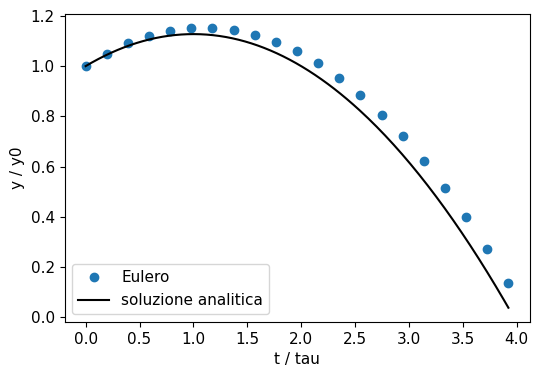

In [51]:
tau = v0 / g   # s

plt.plot(t / tau, y / y0, 'o', label="Eulero")
plt.plot(t_fine / tau, y_fine / y0, 'k-', label="soluzione analitica")
plt.xlabel("t / tau")
plt.ylabel("y / y0")
plt.legend()
plt.show()

### Legende che hanno senso

Una buona legenda dice **cosa distingue le curve**: il metodo, il valore di un parametro, numerico *vs* analitico, ecc.
Etichette come `"dati1"`, `"curva"`, `"y"` o il nome della variabile Python (`"y_an"`) non aiutano nessuno.

Alcuni consigli pratici:

* se le curve differiscono per un parametro, mettete il parametro **con la sua unità** nella legenda (vedi sotto)
* `plt.legend(loc="upper right")` (o `"best"`, `"lower left"`, ...) sposta la legenda se copre i dati
* usate stili diversi per cose concettualmente diverse: simboli per i risultati numerici, linea per la teoria
* le informazioni comuni a tutte le curve (es. i parametri della simulazione) possono andare nel titolo o, in una relazione, nella didascalia della figura

Le *f-string* (`f"..."`) sono comodissime per costruire le etichette a partire dai valori numerici:

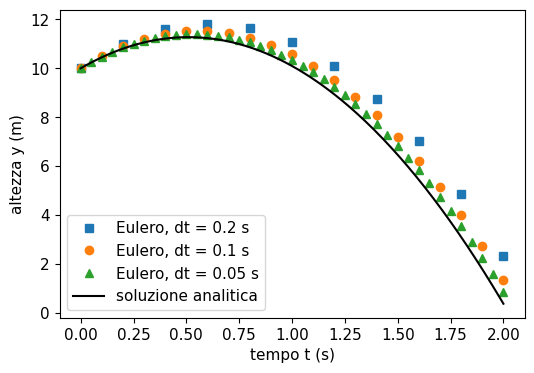

In [53]:
for dt_i, simbolo in [(0.2, 's'), (0.1, 'o'), (0.05, '^')]:
    dati = caduta(dt_i, int(round(2.0 / dt_i)), y0, v0, g, "caduta.dat")
    etichetta = f"Eulero, dt = {dt_i} s"
    plt.plot(dati[:, 0], dati[:, 1], simbolo, label=etichetta)

plt.plot(t_fine, y_fine, 'k-', label="soluzione analitica")
plt.xlabel("tempo t (s)")
plt.ylabel("altezza y (m)")
plt.legend(loc="lower left")
plt.show()

**Provate voi**: copiate qui sotto la cella del "grafico inutile" della sezione 3 e sistematela: due pannelli (posizione e velocità), etichette con unità, simboli per i dati numerici, linea per la soluzione analitica e legende sensate.

In [54]:
# il vostro codice qui

## LaTeX nei grafici

Scrivere `y / y0` o `t / tau` è leggibile, ma in fisica siamo abituati a $y/y_0$ e $t/\tau$. `matplotlib` interpreta come formula LaTeX tutto ciò che si trova **tra due simboli `$`** in qualunque testo (etichette, titoli, legende, annotazioni). Non serve avere LaTeX installato: `matplotlib` contiene un suo motore (*mathtext*) che supporta la gran parte dei comandi più comuni.

### Le stringhe *raw*: `r"..."`

In LaTeX i comandi iniziano con il backslash `\`, ma per Python il backslash introduce i caratteri speciali (`\n` = a capo, `\t` = tabulazione, ...). Guardate cosa succede:

In [55]:
print("$\theta$ e $\nu$")    # stringa normale: \t diventa una tabulazione, \n un a capo!
print(r"$\theta$ e $\nu$")   # stringa raw: i backslash restano tali

$	heta$ e $
u$
$\theta$ e $\nu$


> ⚠️ **Usate sempre le stringhe raw (`r"..."`) per il testo che contiene LaTeX.**

### Prontuario minimo

| Cosa | Si scrive | Risultato |
|---|---|---|
| lettere greche | `r"$\tau$, $\theta_0$, $\Delta t$"` | $\tau$, $\theta_0$, $\Delta t$ |
| pedici e apici | `r"$y_0$, $t^2$, $y_{\mathrm{max}}$"` | $y_0$, $t^2$, $y_{\mathrm{max}}$ |
| più caratteri: graffe! | `r"$v_{y0}$"` *vs* `r"$v_y0$"` | $v_{y0}$ *vs* $v_y0$ |
| frazioni | `r"$\frac{1}{2} g t^2$"` | $\frac{1}{2} g t^2$ |
| testo dritto (unità, pedici "a parole") | `r"$\mathrm{m\,s^{-2}}$"` | $\mathrm{m\,s^{-2}}$ |
| spazio sottile | `r"$10\,\mathrm{m}$"` | $10\,\mathrm{m}$ |
| gradi | `r"$45^\circ$"` | $45^\circ$ |
| simboli | `r"$\approx$, $\propto$, $\times$, $\pm$"` | $\approx$, $\propto$, $\times$, $\pm$ |

### Convenzione tipografica: simboli in corsivo, unità in tondo

Nella letteratura scientifica i **simboli delle grandezze** si scrivono in *corsivo* ($t$, $y$, $v$), mentre le **unità di misura** e i pedici descrittivi si scrivono in tondo ($\mathrm{s}$, $\mathrm{m/s}$, $y_\mathrm{max}$). Il modo più semplice di ottenerlo è mettere tra `$` solo il simbolo e lasciare l'unità come testo normale:

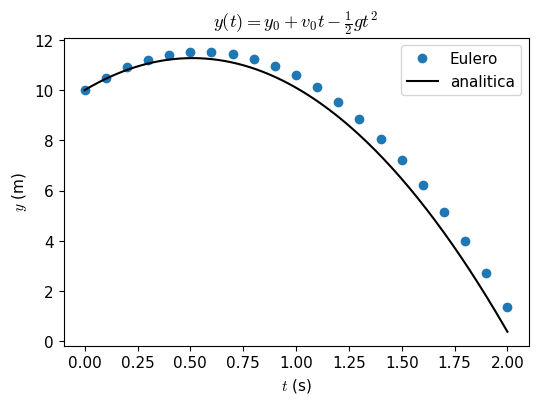

In [56]:
plt.plot(t, y, 'o', label="Eulero")
plt.plot(t_fine, y_fine, 'k-', label="analitica")
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$y$ (m)")
plt.title(r"$y(t) = y_0 + v_0 t - \frac{1}{2} g t^2$")
plt.legend()
plt.show()

Confrontate con la versione "tutto dentro i dollari", dove le unità finiscono in corsivo e diventano indistinguibili da variabili ($m$ sta per *metri* o per *massa*? $s$ sta per *secondi* o per *spazio percorso*?):

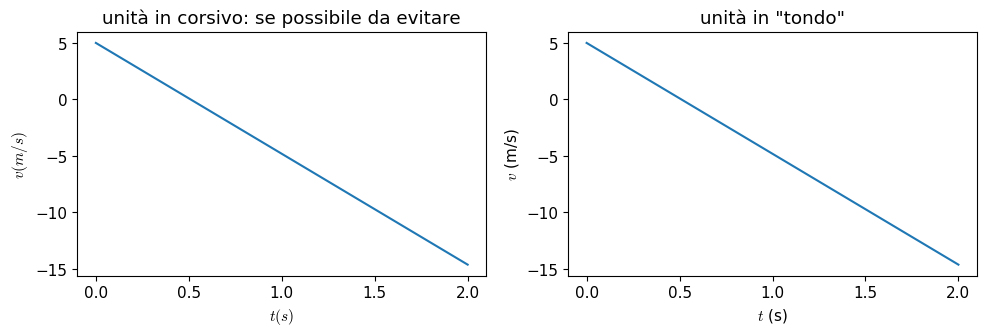

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(t_fine, v_fine)
axes[0].set_xlabel(r"$t (s)$")
axes[0].set_ylabel(r"$v (m/s)$")
axes[0].set_title("unità in corsivo: se possibile da evitare")

axes[1].plot(t_fine, v_fine)
axes[1].set_xlabel(r"$t$ (s)")
axes[1].set_ylabel(r"$v$ (m/s)")
axes[1].set_title("unità in \"tondo\"")

fig.tight_layout()
plt.show()

> ⚠️ **LaTeX + f-string, attenzione alle graffe**: possiamo combinare stringhe raw e f-string con il prefisso `rf"..."`. Il problema è che le graffe servono sia a LaTeX che alle f-string: dentro una f-string le graffe di LaTeX vanno **raddoppiate** (`{{` e `}}`), mentre quelle singole racchiudono le variabili Python: `etichetta = rf"$a = \sqrt{{b}}$"`.

In [66]:
b = 2.0
print(rf"$a = \sqrt{{ 1.0 + {b} }}$")

$a = \sqrt{ 1.0 + 2.0 }$


## Mettiamo tutto insieme: il lancio di un proiettile

Passiamo a due dimensioni: un proiettile lanciato dall'origine con velocità iniziale di modulo $v_0$ e angolo $\theta_0$ rispetto all'orizzontale. Le equazioni del moto sono quelle di prima per la componente verticale, più un moto uniforme in orizzontale:

$$
\frac{dx}{dt} = v_x, \quad \frac{dv_x}{dt} = 0, \qquad \frac{dy}{dt} = v_y, \quad \frac{dv_y}{dt} = -g,
$$

con $v_x(0) = v_0 \cos\theta_0$ e $v_y(0) = v_0 \sin\theta_0$. Integriamo con Eulero fino a quando il proiettile tocca terra ($y < 0$).

In [67]:
def lancio(dt, v0, theta0_gradi, g=9.81):
    # integra il moto di un proiettile con il metodo di Eulero finché y >= 0; restituisce t, x, y, vx, vy
    theta0 = np.radians(theta0_gradi)
    t, x, y = 0.0, 0.0, 0.0
    vx, vy = v0 * np.cos(theta0), v0 * np.sin(theta0)
    righe = []
    while y >= 0:
        righe.append((t, x, y, vx, vy))
        x = x + vx * dt
        y = y + vy * dt
        vy = vy - g * dt
        t += dt
    return np.array(righe).T   # .T: così possiamo scrivere t, x, y, vx, vy = lancio(...)

v0_lancio = 10.0   # m/s
dt_lancio = 0.05   # s
angoli = [15, 30, 45, 60, 75]   # gradi

Nella figura qui sotto notate che:

* traiettoria ($y$ in funzione di $x$) e velocità ($v_y$ in funzione di $t$) stanno in **pannelli separati**, perché sono grandezze diverse
* nel pannello della traiettoria entrambi gli assi sono lunghezze in metri: ha senso imporre **la stessa scala** sui due assi (`set_aspect("equal")`), altrimenti la forma della traiettoria risulta deformata
* lo **stesso colore** indica lo stesso angolo in entrambi i pannelli: per questo basta una sola legenda
* i parametri comuni a tutte le curve stanno nel titolo generale (`fig.suptitle`), quelli che le distinguono nella legenda

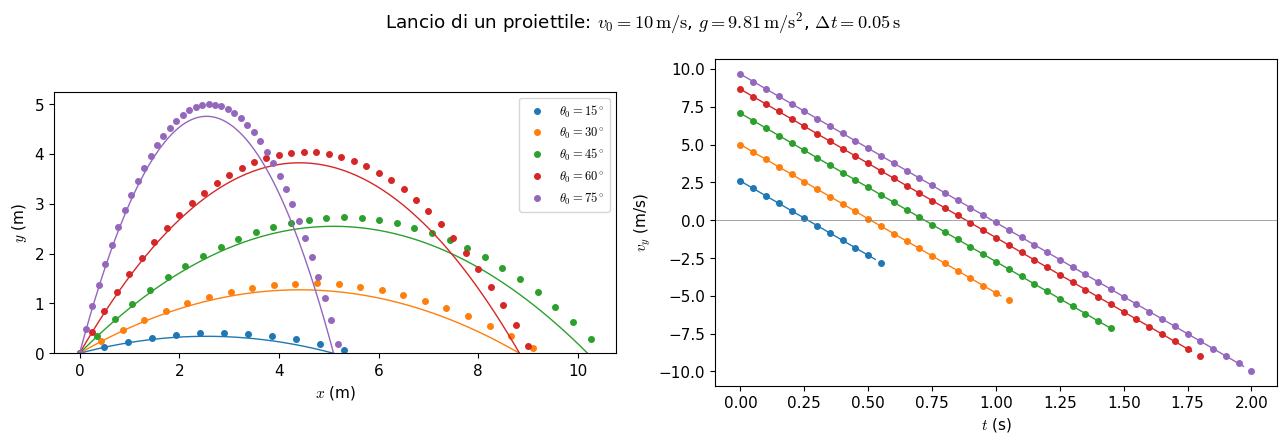

In [68]:
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.size"] = 11

fig, (ax_traj, ax_v) = plt.subplots(1, 2, figsize=(13, 4.5))

for i, theta0 in enumerate(angoli):
    colore = f"C{i}"   # C0, C1, C2, ...: i colori di default di matplotlib
    t_l, x_l, y_l, vx_l, vy_l = lancio(dt_lancio, v0_lancio, theta0, g)

    # soluzione analitica su una griglia fitta, fino al tempo di volo
    t_volo = 2 * v0_lancio * np.sin(np.radians(theta0)) / g
    tt = np.linspace(0, t_volo, 200)
    xx = v0_lancio * np.cos(np.radians(theta0)) * tt
    yy = v0_lancio * np.sin(np.radians(theta0)) * tt - 0.5 * g * tt**2
    vyy = v0_lancio * np.sin(np.radians(theta0)) - g * tt

    ax_traj.plot(x_l, y_l, 'o', color=colore, markersize=4, label=rf"$\theta_0 = {theta0}^\circ$")
    ax_traj.plot(xx, yy, '-', color=colore, linewidth=1)
    ax_v.plot(t_l, vy_l, 'o', color=colore, markersize=4)
    ax_v.plot(tt, vyy, '-', color=colore, linewidth=1)

ax_traj.set_xlabel(r"$x$ (m)")
ax_traj.set_ylabel(r"$y$ (m)")
ax_traj.set_aspect("equal")
ax_traj.set_ylim(bottom=0)
ax_traj.legend(loc="upper right", fontsize=9)

ax_v.axhline(0, color="gray", linewidth=0.5)
ax_v.set_xlabel(r"$t$ (s)")
ax_v.set_ylabel(r"$v_y$ (m/s)")

fig.suptitle(rf"Lancio di un proiettile: $v_0 = {v0_lancio:.0f}\,\mathrm{{m/s}}$, "
             rf"$g = {g}\,\mathrm{{m/s^2}}$, $\Delta t = {dt_lancio}\,\mathrm{{s}}$")
fig.tight_layout()
fig.savefig("lancio_proiettile.pdf")   # per le relazioni il PDF (vettoriale) è meglio del PNG
plt.show()

## Checklist ed esercizi

### Checklist da controllare per **ogni** grafico

- [ ] Ogni asse ha un'etichetta con la **grandezza** (simbolo o nome)?
- [ ] Ogni asse ha l'**unità di misura**, oppure è chiaro che la grandezza è adimensionale (e rispetto a cosa)?
- [ ] L'unità scritta corrisponde ai **numeri** effettivamente riportati sull'asse?
- [ ] Grandezze con unità diverse stanno su assi (o pannelli) diversi?
- [ ] Se ci sono più curve, c'è una **legenda** che dice cosa le distingue (metodo, parametro *con unità*, numerico *vs* analitico)?
- [ ] La legenda non copre i dati?
- [ ] Simboli in corsivo, unità in tondo? Stringhe LaTeX in formato raw (`r"..."`)?
- [ ] Il testo è leggibile alla dimensione finale della figura?
- [ ] Qualcuno che non ha visto il codice capirebbe il grafico?

### Per esercitarvi

1. **Componenti del moto.** Per il lancio a $\theta_0 = 45^\circ$ fate una figura con due pannelli: $x(t)$ e $y(t)$ nel primo, $v_x(t)$ e $v_y(t)$ nel secondo, con etichette in LaTeX e legende sensate. Possono stare sullo stesso pannello $x$ e $y$? E $v_x$ e $v_y$?
2. **Modulo della velocità.** Graficate $|\vec v| = \sqrt{v_x^2 + v_y^2}$ in funzione del tempo per i cinque angoli. Come scrivete l'etichetta dell'asse in LaTeX?
3. **Dai vostri dati.** Leggete con `np.loadtxt` un file prodotto dal vostro programma C dell'Esercitazione 1 (colonne `t y v`) e preparate una figura che rispetti tutta la checklist.
4. **Caccia all'errore.** Trovate (almeno) cinque problemi nella cella qui sotto e correggeteli.